# Averaging Smoothing Filter (From Scratch)

In [2]:
%pip install opencv-python matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


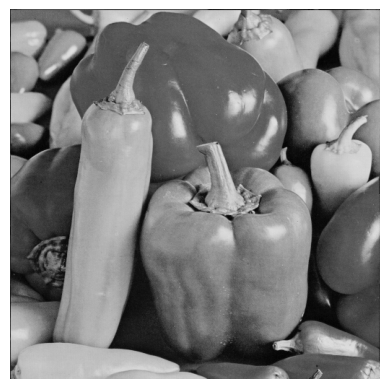

In [ ]:
from pathlib import Path
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np
#Path
project_root = Path.cwd()
project_root = project_root.parent
image_path = project_root / 'Images' / 'img1.tif'
img1 = cv.imread(str(image_path))

new_img1 = img1.copy()
#Loop through the image, avoiding edges
for y in range(5, img1.shape[0] - 5):
    for x in range(5, img1.shape[1] - 5):
        window = img1[y-5:y+6, x-5: x + 6] #Window of 11x11 pixels centered at (x, y)
        new_img1[y, x] = np.mean(window) #set pixel value at (x, y) to the average of the window

img1_rgb = cv.cvtColor(img1, cv.COLOR_BGR2RGB)
plt.imshow(img1_rgb)
plt.axis('off')
plt.show()



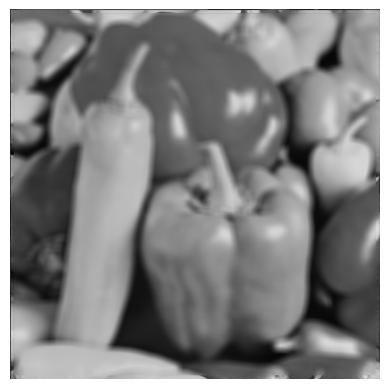

In [15]:
new_img1_rgb = cv.cvtColor(new_img1, cv.COLOR_BGR2RGB)
plt.imshow(new_img1_rgb)
plt.axis('off')
plt.show()

# Averaging Smoothing Filter (opencv)

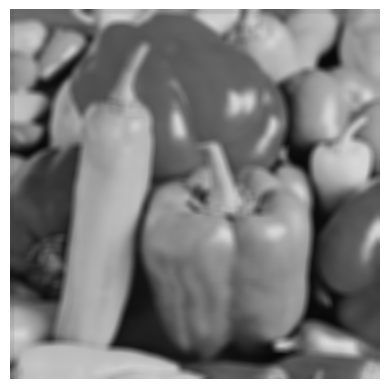

In [16]:
img1_averaged = cv.blur(img1, (11, 11))

img1_averaged_rgb = cv.cvtColor(img1_averaged, cv.COLOR_BGR2RGB)
plt.imshow(img1_averaged_rgb)
plt.axis('off')
plt.show()

# Gaussian Smoothing Filter (From Scratch)

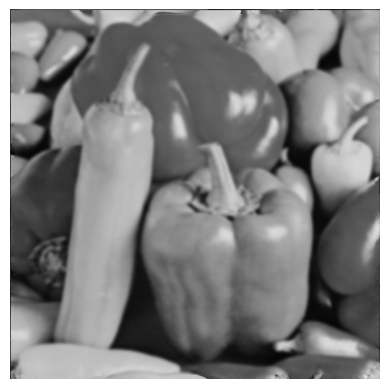

In [23]:
img1_gaussian_scratch = img1.copy()
SIGMA = 2
#Build the Gaussian kernel
gaussian_kernel = np.zeros((13, 13), dtype=np.float32)
for i in range(-5, 6):
    for j in range(-5, 6):
        gaussian_kernel[i + 5, j + 5] = np.exp(-(i**2 + j**2) / (2 * (SIGMA ** 2)))
#Normalize kernel
gaussian_kernel /= np.sum(gaussian_kernel)
#Loop through the image, avoiding edges
for y in range(6, img1.shape[0] - 6):
    for x in range(6, img1.shape[1] - 6):
        window = img1[y-6:y+7, x-6: x + 7]
        img1_gaussian_scratch[y, x] = np.sum(window * gaussian_kernel[:, :,None], axis=(0, 1)) 
img1_gaussian_scratch_rgb = cv.cvtColor(img1_gaussian_scratch, cv.COLOR_BGR2RGB)
plt.imshow(img1_gaussian_scratch_rgb)
plt.axis('off')
plt.show()

# Gaussian Smoothing Filter (OpenCV)

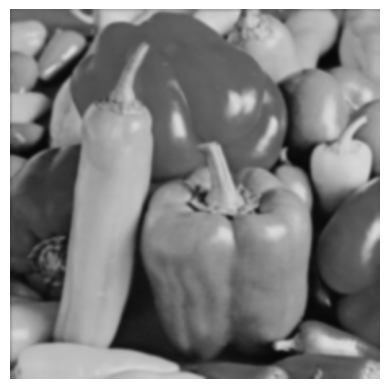

In [24]:
img1_gaussian_cv = cv.GaussianBlur(img1, (13, 13), sigmaX=2)
img1_gaussian_cv_rgb = cv.cvtColor(img1_gaussian_cv, cv.COLOR_BGR2RGB)
plt.imshow(img1_gaussian_cv_rgb)
plt.axis('off')
plt.show()

# Sobel Operator (From Scratch)

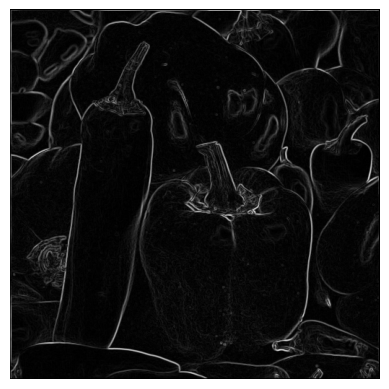

In [28]:
#Convert to grayscale
gray = cv.cvtColor(img1, cv.COLOR_BGR2GRAY)

img1_sobel_scratch = np.zeros_like(gray, dtype=np.float32)
#Finding Gx and Gy using Sobel operator
Gx = np.array([[-1, 0, 1],
               [-2, 0, 2],
                [-1, 0, 1]])
Gy = np.array([[-1, -2, -1],
               [0, 0, 0],
               [1, 2, 1]])
#Loop through the image, avoiding edges
for i in range(1, gray.shape[0] - 1):
    for j in range(1, gray.shape[1] - 1):
        window = gray[i-1:i+2, j-1:j+2]
        Gx_val = np.sum(window * Gx)
        Gy_val = np.sum(window * Gy)
        img1_sobel_scratch[i, j] = np.sqrt(Gx_val**2 + Gy_val**2)
#Normalize image
img1_sobel_scratch = cv.normalize(
    img1_sobel_scratch,
    None,
    0,
    255,
    cv.NORM_MINMAX
).astype(np.uint8)
#Display
# img1_sobel_scratch_rgb = cv.cvtColor(img1_sobel_scratch, cv.COLOR_BGR2RGB)
plt.imshow(img1_sobel_scratch, cmap='gray')
plt.axis('off')
plt.show()



# Sobel Operator (opencv)

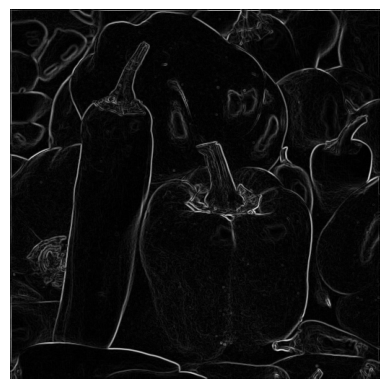

In [29]:
#Set to grayscale
gray = cv.cvtColor(img1, cv.COLOR_BGR2GRAY)

#Horizontal gradient
sobel_x = cv.Sobel(gray, cv.CV_32F, 1, 0, ksize=3)

# Vertical gradient
sobel_y = cv.Sobel(gray, cv.CV_32F, 0, 1, ksize=3)

# Gradient magnitude
img1_sobel_cv = np.sqrt(sobel_x**2 + sobel_y**2)

# Normalization
img1_sobel_cv = cv.normalize(
    img1_sobel_cv,
    None,
    0,
    255,
    cv.NORM_MINMAX
).astype(np.uint8)

# Display
plt.imshow(img1_sobel_cv, cmap='gray')
plt.axis('off')
plt.show()
